In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import os
import platform
import re
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Fixed creation date in the PDF files: an unchanged figure is written byte for byte
# the same
os.environ.setdefault("SOURCE_DATE_EPOCH", "0")

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from haversine import haversine_vector
from matplotlib import ticker

from synccfd import __version__
from synccfd.simulator import presets
from synccfd.simulator.generator import DatasetGenerator

sns.set_style("darkgrid")
sns.set(font_scale=1.4)

# Parameters

One parameter chooses the preset and the size:

- `PRESET = "realistic"` (default): the complete SynCCFD (merchants, customer drift,
  seasonality and injected frauds, with the five scenarios);
- `PRESET = "ablation:base"`, `"ablation:drift"` or `"ablation:frauds"`: the steps of the
  ablation, with the components switched on cumulatively (`presets.ablation`).

The default is `presets.realistic()` with `presets.DEFAULT_SIZE` (10 000 customers,
20 000 terminals, 180 days from 2023-01-01, `random_state=42`). The environment variables
`SYNCCFD_PRESET`, `SYNCCFD_N_CUSTOMERS`, `SYNCCFD_N_TERMINALS`, `SYNCCFD_NB_DAYS` and
`SYNCCFD_SEED` change these values.

`LANG` is the language of the figure labels: `"en"` (default) or `"pt"`; the environment
variable `SYNCCFD_LANG` sets it. The figures are saved as PDF in `figures/overview/`
(`SYNCCFD_FIG_DIR` changes `figures/`), and the statistics of the dataset in
`figures/dataset_stats.json`.

In [3]:
# "realistic" or an ablation step ("ablation:base", "ablation:drift", ...)
PRESET = os.environ.get("SYNCCFD_PRESET", "realistic")
PARAMS = presets.from_env(default=PRESET)
print(PRESET, {key: PARAMS[key] for key in presets.DEFAULT_SIZE})
WITH_MERCHANTS = PARAMS.get("merchants") is not None

# Language of the figure labels: "en" or "pt"
LANG = os.environ.get("SYNCCFD_LANG", "en")
TEXT = {
    "en": {
        "customers_location": "Customer location",
        "terminals_location": "Terminal location",
        "available_terminals_location": "Available terminal location",
        "customers_locations": "Customer locations",
        "terminals_locations": "Terminal locations",
        "cp_transactions": "CP transactions",
        "cnp_transactions": "CNP transactions",
        "cnp_transactions_no_s3": "CNP transactions (excluding scenario 3)",
        "time_days": "Time (days)",
        "amount": "Amount",
        "amount_log": "Amount (log scale)",
        "radius": "Radius",
        "customer": "Customer",
        "top_customers": "Municipalities with the most customers",
        "top_terminals": "Municipalities with the most terminals",
        "top_population": "Municipalities with the largest population",
        "scenario": "Fraud Scenario",
        "non_fraud": "Non-Fraud",
        "transactions_50": "Transactions (/50)",
        "frauds": "Frauds",
        "compromised": "Compromised customers",
        "days_since_start": "Days since the start of the simulation",
        "distance": "Distance",
        "distance_km": "Distance (km)",
        "dist_bill_term_cnp": "Billing-Terminal Distance Distribution - CNP",
        "dist_bill_shipp_cnp": "Billing-Shipping Distance Distribution - CNP",
        "dist_bill_term_cp": "Billing-Terminal Distance Distribution - CP",
        "dist_bill_shipp_cp": "Billing-Shipping Distance Distribution - CP",
        "frauds_share": "Frauds (% of the category's transactions)",
        # Values of the data, shown translated in the English figures
        "categories": {
            "supermercado": "supermarket", "restaurante_bar": "restaurant and bar",
            "posto_combustivel": "fuel station", "farmacia": "pharmacy",
            "vestuario": "clothing", "eletronicos": "electronics",
            "viagem_turismo": "travel", "ecommerce_marketplace": "marketplace",
            "servicos_digitais": "digital services", "transporte_app": "ride-hailing",
        },
    },
    "pt": {
        "customers_location": "Localização dos Clientes",
        "terminals_location": "Localização dos Terminais",
        "available_terminals_location": "Localização dos Terminais Disponíveis",
        "customers_locations": "Localizações dos Clientes",
        "terminals_locations": "Localizações dos Terminais",
        "cp_transactions": "Transações CP",
        "cnp_transactions": "Transações CNP",
        "cnp_transactions_no_s3": "Transações CNP (desconsidera o cenário 3)",
        "time_days": "Tempo (dias)",
        "amount": "Valor",
        "amount_log": "Valor (escala log)",
        "radius": "Raio",
        "customer": "Cliente",
        "top_customers": "Municípios com o maior número de clientes",
        "top_terminals": "Municípios com o maior número de terminais",
        "top_population": "Municípios com a maior população",
        "scenario": "Cenário de Fraude",
        "non_fraud": "Não-Fraude",
        "transactions_50": "Transações (/50)",
        "frauds": "Fraudes",
        "compromised": "Clientes comprometidos",
        "days_since_start": "Dias desde o início da simulação",
        "distance": "Distância",
        "distance_km": "Distância (km)",
        "dist_bill_term_cnp": "Distribuição da Distância Billing-Terminal - CNP",
        "dist_bill_shipp_cnp": "Distribuição da Distância Billing-Shipping - CNP",
        "dist_bill_term_cp": "Distribuição da Distância Billing-Terminal - CP",
        "dist_bill_shipp_cp": "Distribuição da Distância Billing-Shipping - CP",
        "frauds_share": "Fraudes (% das transações da categoria)",
        "categories": {},  # as in the data
    },
}
T = TEXT[LANG]

# Where the figures and the statistics are saved
FIG_ROOT = Path(os.environ.get("SYNCCFD_FIG_DIR", "figures"))
FIG_DIR = FIG_ROOT / "overview"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def map_labels(ax, xlabel="Longitude", ylabel="Latitude"):
    # Recent versions of geopandas fill empty axis labels ("x", "y"), in a small font
    size = plt.rcParams["axes.labelsize"]
    ax.set_xlabel(xlabel, fontsize=size)
    ax.set_ylabel(ylabel, fontsize=size)


# In Portuguese, the numbers in the figures use the decimal comma and a space between
# the thousands, as in the text of the dissertation
def num(text):
    if LANG != "pt":
        return text
    math = text.count("$") >= 2  # mathtext: braces keep the comma without a space
    point, thousands = ("{,}", r"\,") if math else (",", "\u00a0")
    return re.sub(r"(?<=\d)[.,](?=\d)", lambda m: point if m.group() == "." else thousands, text)


class LocalizedFormatter(ticker.Formatter):
    # The labels of another tick formatter, through num()
    def __init__(self, inner):
        self.inner = inner

    def set_axis(self, axis):
        self.axis = axis
        self.inner.set_axis(axis)

    def set_locs(self, locs):
        self.inner.set_locs(locs)

    def __call__(self, x, pos=None):
        return num(self.inner(x, pos))

    def format_ticks(self, values):
        return [num(label) for label in self.inner.format_ticks(values)]

    def get_offset(self):
        return num(self.inner.get_offset())


def localize(fig):
    # The tick labels of every axis through num(); call it just before saving
    if LANG != "pt":
        return
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if not isinstance(axis.get_major_formatter(), LocalizedFormatter):
                axis.set_major_formatter(LocalizedFormatter(axis.get_major_formatter()))
            if not isinstance(axis.get_minor_formatter(), LocalizedFormatter):
                axis.set_minor_formatter(LocalizedFormatter(axis.get_minor_formatter()))


def save_figure(name):
    # Vector PDF; the boxplot outliers (many thousands of points) are rasterized
    localize(plt.gcf())
    plt.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight", dpi=200)


# One color per fraud scenario, and blue for the legitimate transactions
SCENARIO_PALETTE = dict(zip(range(1, 6), sns.color_palette("Reds", 7)[2:]))
PALETTE = {0: sns.color_palette()[0], **SCENARIO_PALETTE}

realistic {'n_customers': 10000, 'n_terminals': 20000, 'nb_days': 180, 'start_date': '2023-01-01', 'random_state': 42}


# Toy Example

In [4]:
# Generate the data
city_radius = 12
available_terminals_radius = 10
start_date = "2025-01-01"

generator = DatasetGenerator(
    **{
        **PARAMS,
        "n_customers": 5,
        "n_terminals": 25,
        "nb_days": 5,
        "city_radius": city_radius,
        "available_terminals_radius": available_terminals_radius,
        "start_date": start_date,
        "random_state": 42,
    }
)
customer_profiles_table, terminal_profiles_table, transactions_df = generator.generate()

# Persist the dataset explicitly (generate() does not write to disk)
generator.save(save_format="pkl")

Dataset saved to 'data'.


In [5]:
# Data can be loaded back from disk after save()
BEGIN_DATE = "2025-01-01"
END_DATE = "2025-01-05"

data = DatasetGenerator()
txs = data.read_transactions(
    begin_date=BEGIN_DATE, end_date=END_DATE, save_format="pkl", data_dir="data"
)

## Customer profiles table

In [6]:
print(customer_profiles_table.shape)
customer_profiles_table

(5, 40)

,CUSTOMER_ID,billing_lat,billing_long,mean_amount,std_amount,mean_nb_tx_per_day,cnp_prob,available_terminals,spending_factor,pref_supermercado,...,GT_B_pref_supermercado,GT_B_pref_restaurante_bar,GT_B_pref_posto_combustivel,GT_B_pref_farmacia,GT_B_pref_vestuario,GT_B_pref_eletronicos,GT_B_pref_viagem_turismo,GT_B_pref_ecommerce_marketplace,GT_B_pref_servicos_digitais,GT_B_pref_transporte_app
0,0,-29.776421,-57.092229,88.510000,NaN,0.644564,0.578168,"[1, 14]",1.397663,0.148243,...,0.177639,0.032612,0.185713,0.138077,0.037857,0.013183,0.048089,0.129624,0.234369,0.002836
1,1,-29.717268,-51.035729,156.655333,217.187324,1.708920,0.134952,[9],0.744992,0.236787,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,-29.166542,-51.085918,49.355455,55.986842,3.239595,0.558635,"[10, 12, 18]",0.914607,0.012822,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,-12.882126,-38.330748,133.297778,121.090950,3.405348,0.724042,"[2, 8, 20]",0.825763,0.420723,...,0.284407,0.080170,0.043642,0.070217,0.099148,0.012687,0.000739,0.104516,0.219068,0.085406
4,4,-16.861526,-49.230081,32.900000,NaN,0.277849,0.776352,"[6, 13, 19, 24]",0.490502,0.295081,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Terminal profiles table

In [7]:
print(terminal_profiles_table.shape)
terminal_profiles_table

(185, 4)


,TERMINAL_ID,terminal_lat,terminal_long,MERCHANT_ID
0,0,-29.097045,-51.246178,7
1,1,-29.725513,-57.048147,14
2,2,-12.910692,-38.359004,2
3,3,-29.744851,-51.267058,11
4,4,-16.730283,-49.201522,16
...,...,...,...,...
180,180,-29.152744,-51.170384,175
181,181,-15.761704,-48.349183,176
182,182,-3.695351,-38.661705,177
183,183,-22.852871,-43.046541,178


## Transactions table

In [8]:
print(transactions_df.shape)
transactions_df

(46, 24)


,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,MERCHANT_ID,MERCHANT_CATEGORY,TX_AMOUNT,TX_TYPE,TX_SHIPP_LAT,TX_SHIPP_LONG,...,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO,GT_REGIME_WEIGHT,GT_REGIME,GT_FRAUD_SCENARIO,GT_FRAUDSTER_ID,GT_CAMPAIGN_ID,GT_COMPROMISE_ID
0,0,2025-01-01 06:17:28,2,166,161,transporte_app,4.78,CNP,-29.166542,-51.085918,...,22648,0,0,0,0.000000,A,0,<NA>,<NA>,<NA>
1,1,2025-01-01 08:22:17,2,166,161,transporte_app,19.32,CNP,-29.166542,-51.085918,...,30137,0,0,0,0.000000,A,0,<NA>,<NA>,<NA>
2,2,2025-01-01 08:35:00,3,165,160,transporte_app,31.00,CNP,-12.882126,-38.330748,...,30900,0,0,0,0.000000,A,0,<NA>,<NA>,<NA>
3,3,2025-01-01 11:58:30,1,29,24,supermercado,85.18,CNP,-29.717268,-51.035729,...,43110,0,0,0,0.000000,A,0,<NA>,<NA>,<NA>
4,4,2025-01-01 16:26:06,3,8,0,supermercado,138.07,CP,-12.937746,-38.351905,...,59166,0,0,0,0.000000,A,0,<NA>,<NA>,<NA>
5,5,2025-01-01 18:06:09,3,2,2,supermercado,61.88,CP,-12.910692,-38.359004,...,65169,0,0,0,0.000000,A,0,<NA>,<NA>,<NA>
6,6,2025-01-01 18:24:39,3,165,160,transporte_app,12.75,CNP,-12.882126,-38.330748,...,66279,0,0,0,0.000000,A,0,<NA>,<NA>,<NA>
7,7,2025-01-01 21:52:20,3,69,64,vestuario,192.68,CNP,-12.882126,-38.330748,...,78740,0,0,0,0.000000,A,0,<NA>,<NA>,<NA>
8,8,2025-01-01 22:07:00,1,145,140,servicos_digitais,40.17,CNP,-29.717268,-51.035729,...,79620,0,0,0,0.000000,A,0,<NA>,<NA>,<NA>
9,9,2025-01-02 00:54:09,1,149,144,servicos_digitais,17.86,CNP,-29.717268,-51.035729,...,89649,1,0,0,0.000000,A,0,<NA>,<NA>,<NA>


In [9]:
# Getting transactions for a specific customer from our previously generated dataset
customer_id = 1
transaction_table_customer = transactions_df[
    transactions_df["CUSTOMER_ID"] == customer_id
]
transaction_table_customer

,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,MERCHANT_ID,MERCHANT_CATEGORY,TX_AMOUNT,TX_TYPE,TX_SHIPP_LAT,TX_SHIPP_LONG,...,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO,GT_REGIME_WEIGHT,GT_REGIME,GT_FRAUD_SCENARIO,GT_FRAUDSTER_ID,GT_CAMPAIGN_ID,GT_COMPROMISE_ID
3,3,2025-01-01 11:58:30,1,29,24,supermercado,85.18,CNP,-29.717268,-51.035729,...,43110,0,0,0,0.0,A,0,<NA>,<NA>,<NA>
8,8,2025-01-01 22:07:00,1,145,140,servicos_digitais,40.17,CNP,-29.717268,-51.035729,...,79620,0,0,0,0.0,A,0,<NA>,<NA>,<NA>
9,9,2025-01-02 00:54:09,1,149,144,servicos_digitais,17.86,CNP,-29.717268,-51.035729,...,89649,1,0,0,0.0,A,0,<NA>,<NA>,<NA>
15,15,2025-01-02 20:17:04,1,45,40,farmacia,49.63,CNP,-29.717268,-51.035729,...,159424,1,0,0,0.0,A,0,<NA>,<NA>,<NA>
16,16,2025-01-02 21:08:01,1,27,22,supermercado,77.21,CNP,-29.717268,-51.035729,...,162481,1,0,0,0.0,A,0,<NA>,<NA>,<NA>
18,18,2025-01-02 22:43:01,1,85,80,eletronicos,750.81,CNP,-29.717268,-51.035729,...,168181,1,0,0,0.0,A,0,<NA>,<NA>,<NA>
22,22,2025-01-03 16:41:40,1,32,27,supermercado,197.14,CNP,-29.717268,-51.035729,...,232900,2,0,0,0.0,A,0,<NA>,<NA>,<NA>
23,23,2025-01-03 21:24:33,1,149,144,servicos_digitais,15.58,CNP,-29.717268,-51.035729,...,249873,2,0,0,0.0,A,0,<NA>,<NA>,<NA>
25,25,2025-01-04 09:24:43,1,141,136,ecommerce_marketplace,47.23,CNP,-29.717268,-51.035729,...,293083,3,0,0,0.0,A,0,<NA>,<NA>,<NA>
27,27,2025-01-04 11:46:34,1,66,61,vestuario,129.19,CNP,-29.717268,-51.035729,...,301594,3,0,0,0.0,A,0,<NA>,<NA>,<NA>


## Plotting locations

In [10]:
loc_features = generator.get_location_features()

### Setting the information to plot locations ###
world = loc_features.data["world_data"]
brazil = world[world.name == "Brazil"]

# Transforming the data into a GeoDataFrame in order to draw
billing_locs = gpd.GeoDataFrame(
    customer_profiles_table,
    geometry=gpd.points_from_xy(
        customer_profiles_table.billing_long, customer_profiles_table.billing_lat
    ),
)

billing_cities_locs = loc_features.billing_cities_locations
billing_cities_locs = gpd.GeoDataFrame(
    billing_cities_locs,
    geometry=gpd.points_from_xy(billing_cities_locs.long, billing_cities_locs.lat),
)

n_physical = len(loc_features.terminal_cities_locations)
physical_terminals = terminal_profiles_table.iloc[:n_physical]
terminal_locs = gpd.GeoDataFrame(
    physical_terminals,
    geometry=gpd.points_from_xy(
        physical_terminals.terminal_long, physical_terminals.terminal_lat
    ),
)


terminal_cities_locs = loc_features.terminal_cities_locations
terminal_cities_locs = gpd.GeoDataFrame(
    terminal_cities_locs,
    geometry=gpd.points_from_xy(terminal_cities_locs.long, terminal_cities_locs.lat),
)

available_terminals_ids = [
    terminal_id
    for sub_list in customer_profiles_table["available_terminals"]
    for terminal_id in sub_list
]  # Creating a single list with all the available terminals
available_terminals_ids = list(
    set(available_terminals_ids)
)  # Removing the possible duplicated id's

available_terminal_locs = terminal_locs.loc[available_terminals_ids]


# Getting info for a single customer txs locations
customer_txs = transactions_df.loc[
    transactions_df["CUSTOMER_ID"] == customer_id,
    [
        "CUSTOMER_ID",
        "TERMINAL_ID",
        "TX_BILL_LAT",
        "TX_BILL_LONG",
        "TX_TERM_LAT",
        "TX_TERM_LONG",
        "TX_SHIPP_LAT",
        "TX_SHIPP_LONG",
    ],
]

tx_bill_locs = customer_txs[["TX_BILL_LAT", "TX_BILL_LONG"]]
tx_term_locs = customer_txs[["TX_TERM_LAT", "TX_TERM_LONG"]]
tx_shipp_locs = customer_txs[["TX_SHIPP_LAT", "TX_SHIPP_LONG"]]

tx_bill_locs = gpd.GeoDataFrame(
    tx_bill_locs,
    geometry=gpd.points_from_xy(tx_bill_locs.TX_BILL_LONG, tx_bill_locs.TX_BILL_LAT),
)
tx_term_locs = gpd.GeoDataFrame(
    tx_term_locs,
    geometry=gpd.points_from_xy(tx_term_locs.TX_TERM_LONG, tx_term_locs.TX_TERM_LAT),
)
tx_shipp_locs = gpd.GeoDataFrame(
    tx_shipp_locs,
    geometry=gpd.points_from_xy(
        tx_shipp_locs.TX_SHIPP_LONG, tx_shipp_locs.TX_SHIPP_LAT
    ),
)

### Billing and terminal locations

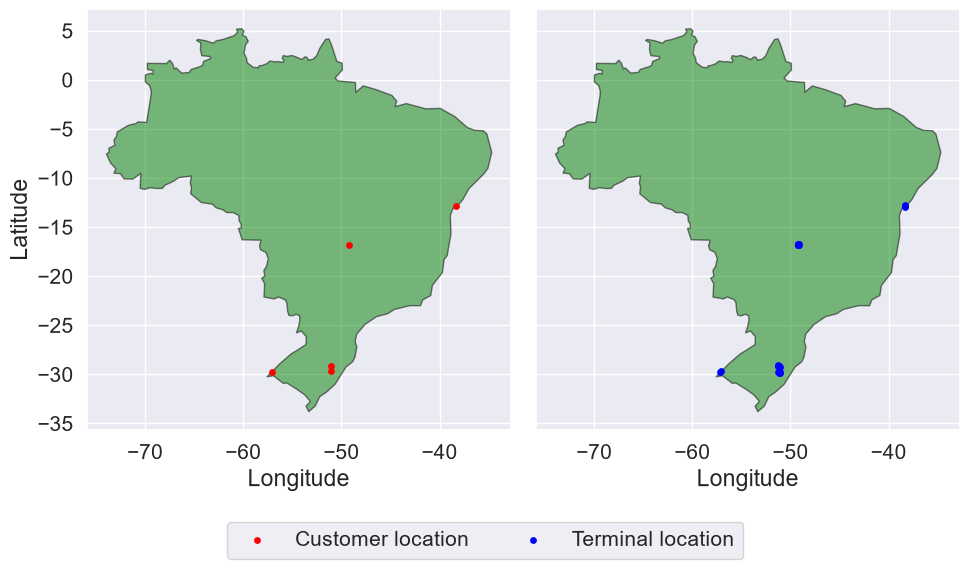

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10, 14), sharey=True)

brazil.plot(color="green", edgecolor="black", alpha=0.5, ax=axs[0])
billing_locs.plot(
    color="red", markersize=15, label=T["customers_location"], ax=axs[0]
)

brazil.plot(color="green", edgecolor="black", alpha=0.5, ax=axs[1])
terminal_locs.plot(
    color="blue", markersize=15, label=T["terminals_location"], ax=axs[1]
)

map_labels(axs[0])
map_labels(axs[1], ylabel="")

# To create a single legend for subplots
handles = []
labels = []
for ax in axs:
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.25))

plt.tight_layout()
plt.show()

### Locations of the available terminals

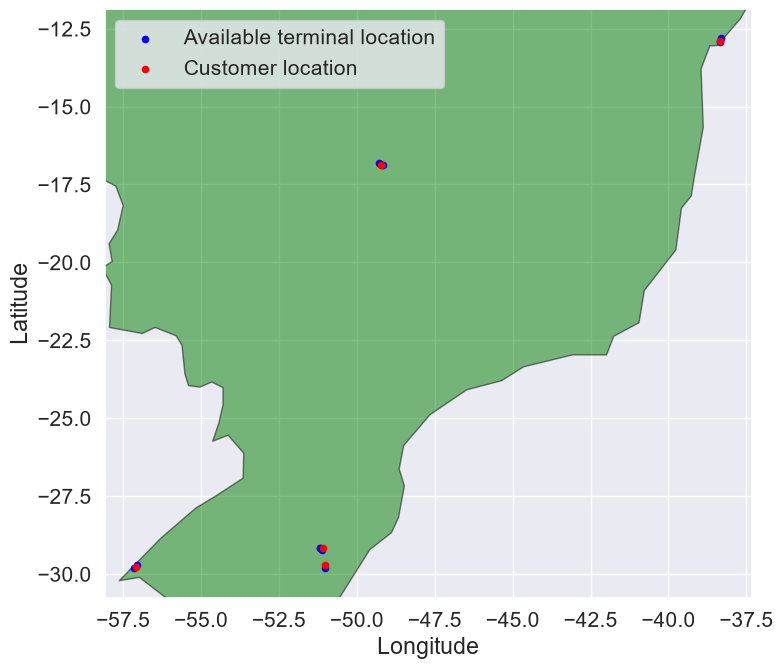

In [12]:
fig, axs = plt.subplots(1, 1, figsize=(8, 7))

brazil.plot(color="green", edgecolor="black", alpha=0.5, ax=axs)
available_terminal_locs.plot(
    color="blue", markersize=20, label=T["available_terminals_location"], ax=axs
)
billing_locs.plot(color="red", markersize=20, label=T["customers_location"], ax=axs)

# Around the customers
bounds = billing_locs.total_bounds
plt.xlim([bounds[0] - 1, bounds[2] + 1])
plt.ylim([bounds[1] - 1, bounds[3] + 1])

map_labels(axs)

plt.legend()
plt.tight_layout()
plt.show()

### Transaction locations

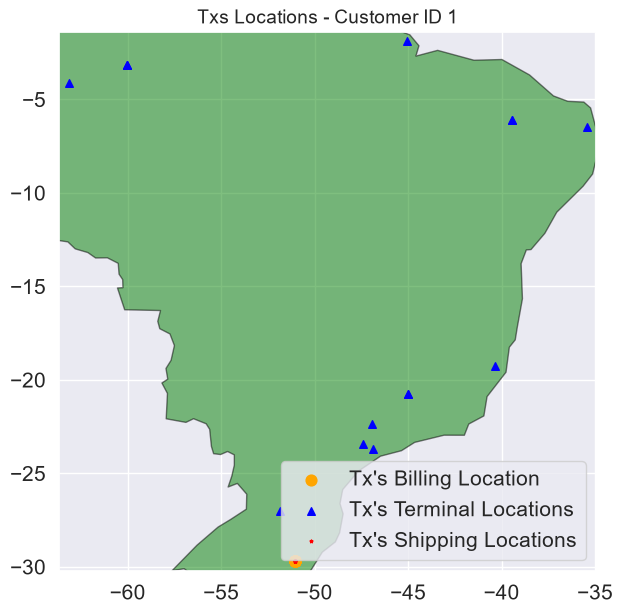

In [13]:
fig, axs = plt.subplots(1, 1, figsize=(7, 7))

brazil.plot(color="green", edgecolor="black", alpha=0.5, ax=axs)
tx_bill_locs.plot(
    ax=axs, color="orange", marker="o", markersize=60, label="Tx's Billing Location"
)
tx_term_locs.plot(
    ax=axs, color="blue", marker="^", markersize=30, label="Tx's Terminal Locations"
)
tx_shipp_locs.plot(
    ax=axs, color="red", marker="*", markersize=5, label="Tx's Shipping Locations"
)

# Around the customer's transactions
bounds = tx_term_locs.total_bounds if len(tx_term_locs) else tx_bill_locs.total_bounds
plt.xlim([min(bounds[0], tx_bill_locs.total_bounds[0]) - 0.5, max(bounds[2], tx_bill_locs.total_bounds[2]) + 0.5])
plt.ylim([min(bounds[1], tx_bill_locs.total_bounds[1]) - 0.5, max(bounds[3], tx_bill_locs.total_bounds[3]) + 0.5])

map_labels(axs, "", "")
plt.legend()
plt.title(f"Txs Locations - Customer ID {customer_id}", fontsize=14)
plt.show()

# The larger dataset

In [14]:
# Building a larger transactions dataset: the configuration of the parameters cell
generator = DatasetGenerator(**PARAMS)
customer_profiles_table, terminal_profiles_table, transactions_df = generator.generate()

n_customers, n_terminals = PARAMS["n_customers"], PARAMS["n_terminals"]
city_radius = generator.city_radius
available_terminals_radius = generator.available_terminals_radius
loc_features = generator.get_location_features()
n_physical = len(loc_features.terminal_cities_locations)
print(f"{len(transactions_df):,} transactions; fraud rate {transactions_df.TX_FRAUD.mean():.3%}")

3,735,430 transactions; fraud rate 0.356%


In [15]:
transactions_df.head()

,TRANSACTION_ID,TX_DATETIME,CUSTOMER_ID,TERMINAL_ID,MERCHANT_ID,MERCHANT_CATEGORY,TX_AMOUNT,TX_TYPE,TX_SHIPP_LAT,TX_SHIPP_LONG,...,TX_TIME_SECONDS,TX_TIME_DAYS,TX_FRAUD,TX_FRAUD_SCENARIO,GT_REGIME_WEIGHT,GT_REGIME,GT_FRAUD_SCENARIO,GT_FRAUDSTER_ID,GT_CAMPAIGN_ID,GT_COMPROMISE_ID
0,0,2023-01-01 00:01:06,3687,20120,14125,servicos_digitais,93.06,CNP,-22.994108,-45.617157,...,66,0,0,0,0.0,A,0,<NA>,<NA>,<NA>
1,1,2023-01-01 00:01:33,9252,20141,14146,transporte_app,27.27,CNP,-7.943337,-34.883378,...,93,0,0,0,0.0,A,0,<NA>,<NA>,<NA>
2,2,2023-01-01 00:01:37,2954,20122,14127,servicos_digitais,26.36,CNP,-23.162941,-47.219506,...,97,0,0,0,0.0,A,0,<NA>,<NA>,<NA>
3,3,2023-01-01 00:01:43,9967,20124,14129,servicos_digitais,49.99,CNP,-23.643163,-46.981112,...,103,0,0,0,0.0,A,0,<NA>,<NA>,<NA>
4,4,2023-01-01 00:01:50,3767,20100,14105,ecommerce_marketplace,108.63,CNP,-20.655269,-43.794829,...,110,0,0,0,0.0,A,0,<NA>,<NA>,<NA>


In [16]:
vis_transactions_df = transactions_df.head().round(3)
vis_transactions_df["TX_AMOUNT"] = vis_transactions_df["TX_AMOUNT"].astype(str)
vis_transactions_df["TX_BILL_LOC"] = (
    "("
    + vis_transactions_df["TX_BILL_LAT"].astype(str)
    + ", "
    + vis_transactions_df["TX_BILL_LONG"].astype(str)
    + ")"
)
vis_transactions_df["TX_TERM_LOC"] = (
    "("
    + vis_transactions_df["TX_TERM_LAT"].astype(str)
    + ", "
    + vis_transactions_df["TX_TERM_LONG"].astype(str)
    + ")"
)
vis_transactions_df["TX_SHIPP_LOC"] = (
    "("
    + vis_transactions_df["TX_SHIPP_LAT"].astype(str)
    + ", "
    + vis_transactions_df["TX_SHIPP_LONG"].astype(str)
    + ")"
)

In [17]:
df_styled = (
    vis_transactions_df[
        [
            "TRANSACTION_ID",
            "TX_DATETIME",
            "CUSTOMER_ID",
            "TERMINAL_ID",
            "TX_AMOUNT",
            "TX_TYPE",
            "TX_BILL_LOC",
            "TX_TERM_LOC",
            "TX_SHIPP_LOC",
            "TX_FRAUD",
        ]
        + (["MERCHANT_CATEGORY"] if WITH_MERCHANTS else [])
    ]
    .rename(
        columns={
            "TRANSACTION_ID": "ID",
            "CUSTOMER_ID": "CUSTOMER",
            "TERMINAL_ID": "TERMINAL",
            "MERCHANT_CATEGORY": "CATEGORY",
        }
    )
    .style.format({"TX_DATETIME": lambda t: t.strftime("%d/%m/%y %H:%M:%S")})
    .hide()
)
df_styled


def save_table(frame, name):
    # The table as a figure (PDF), with the formatting of df_styled; no localize():
    # the numbers as the library outputs them, with the decimal point
    fig, ax = plt.subplots(figsize=(1.9 * frame.shape[1], 0.5 * (len(frame) + 1)))
    ax.axis("off")
    table = ax.table(cellText=frame.to_numpy(), colLabels=list(frame.columns), loc="center", cellLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.auto_set_column_width(range(frame.shape[1]))
    for (row, _), cell in table.get_celld().items():
        cell.set_edgecolor("#d0d0d0")
        if row == 0:
            cell.set_text_props(weight="bold")
    # Crop to the table itself (the axes are wider than the table)
    fig.canvas.draw()
    box = table.get_window_extent(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    plt.savefig(FIG_DIR / f"{name}.pdf", bbox_inches=box.expanded(1.01, 1.05))
    plt.close(fig)


table_df = df_styled.data.copy()
table_df["TX_DATETIME"] = table_df["TX_DATETIME"].dt.strftime("%d/%m/%y %H:%M:%S")
save_table(table_df.astype(str), "transactions_table")

### Transaction amounts and times

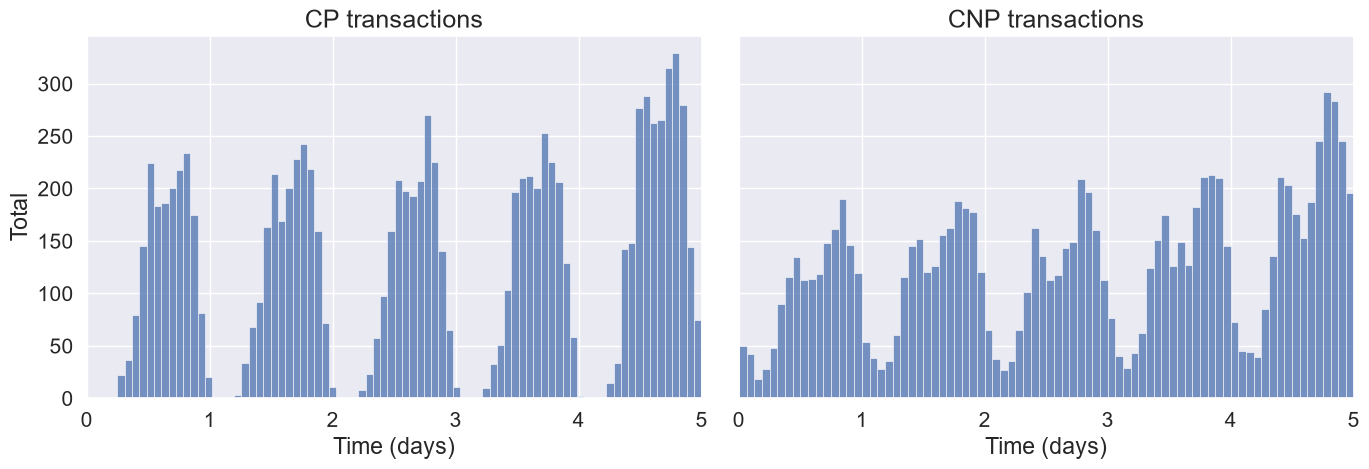

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

time_val_CP = (
    transactions_df[
        (transactions_df.TX_TYPE == "CP") & (transactions_df.TX_TIME_DAYS < 5)
    ]["TX_TIME_SECONDS"]
    .pipe(lambda s: s.sample(n=min(10000, len(s)), random_state=42))
    .values
)
time_val_CNP = (
    transactions_df[
        (transactions_df.TX_TYPE == "CNP") & (transactions_df.TX_TIME_DAYS < 5)
    ]["TX_TIME_SECONDS"]
    .pipe(lambda s: s.sample(n=min(10000, len(s)), random_state=42))
    .values
)

# Dividing the time variables by 86400 to transform seconds to days in the plot
sns.histplot(time_val_CP / 86400, ax=ax[0], color="b", bins=80, kde=False)
ax[0].set_title(T["cp_transactions"], fontsize=18)
ax[0].set_xlim([min(time_val_CP / 86400), max(time_val_CNP / 86400)])
ax[0].set_xticks(range(6))
ax[0].set(xlabel=T["time_days"], ylabel="Total")
sns.histplot(time_val_CNP / 86400, ax=ax[1], color="b", bins=80, kde=False)
ax[1].set_title(T["cnp_transactions"], fontsize=18)
ax[1].set_xlim([min(time_val_CNP / 86400), max(time_val_CNP / 86400)])
ax[1].set_xticks(range(6))

ax[1].set(xlabel=T["time_days"], ylabel="")

plt.tight_layout()
save_figure("simulator_txs_time_per_type")
plt.show()

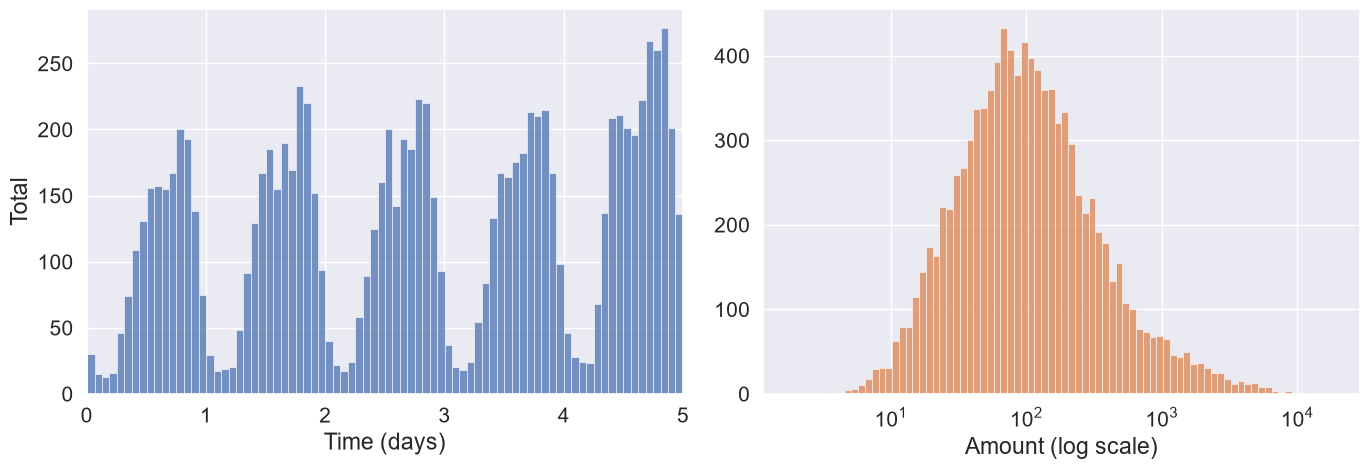

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

amount_val = (
    transactions_df[transactions_df.TX_TIME_DAYS < 5]["TX_AMOUNT"]
    .pipe(lambda s: s.sample(n=min(10000, len(s)), random_state=42))
    .values
)
time_val = (
    transactions_df[transactions_df.TX_TIME_DAYS < 5]["TX_TIME_SECONDS"]
    .pipe(lambda s: s.sample(n=min(10000, len(s)), random_state=42))
    .values
)

# We divide the time variables by 86400 to transform seconds to days in the plot
sns.histplot(time_val / 86400, ax=ax[0], color="b", bins=80, kde=False)
ax[0].set_xlim([min(time_val / 86400), max(time_val / 86400)])
ax[0].set_xticks(range(6))
ax[0].set(xlabel=T["time_days"], ylabel="Total")


if WITH_MERCHANTS:
    # Amounts by category span R$ 1 to R$ 10 000: log scale
    sns.histplot(amount_val, ax=ax[1], color=sns.color_palette()[1], bins=80, log_scale=True, kde=False)
    ax[1].set(xlabel=T["amount_log"], ylabel="")
else:
    sns.histplot(amount_val, ax=ax[1], color=sns.color_palette()[1], binwidth=10, kde=False)
    ax[1].set_xlim([min(amount_val), max(amount_val)])
    ax[1].set(xlabel=T["amount"], ylabel="")

plt.tight_layout()
save_figure("simulator_txs_time_and_amounts")
plt.show()

### CP and CNP proportion

In [20]:
print(
    transactions_df["TX_TYPE"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .astype(str)
    + "%"
)

TX_TYPE
CNP    57.0%
CP     43.0%
Name: proportion, dtype: str


### Location features

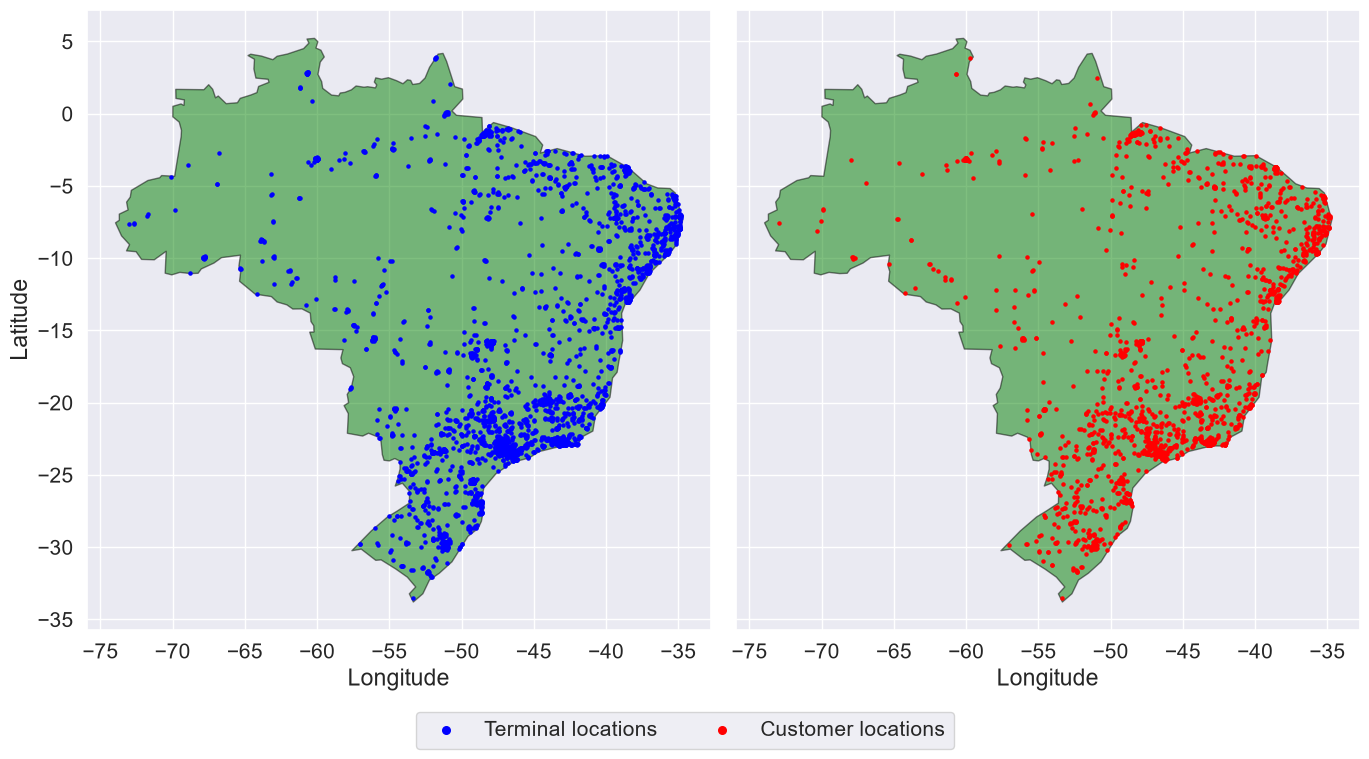

In [21]:
customers_df = customer_profiles_table.sample(n=int(0.2 * n_customers), random_state=42)
customers_geodf = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(customers_df.billing_long, customers_df.billing_lat)
)
terminals_df = terminal_profiles_table.iloc[:n_physical].sample(n=int(0.2 * n_physical), random_state=42)
terminals_geodf = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(terminals_df.terminal_long, terminals_df.terminal_lat)
)

fig, axs = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
brazil.plot(facecolor="green", edgecolor="black", alpha=0.5, ax=axs[0])
terminals_geodf.plot(
    color="blue", markersize=5, ax=axs[0], label=T["terminals_locations"]
)
brazil.plot(facecolor="green", edgecolor="black", alpha=0.5, ax=axs[1])
customers_geodf.plot(
    color="red", markersize=5, ax=axs[1], label=T["customers_locations"]
)

map_labels(axs[0])
map_labels(axs[1], ylabel="")

# To create a single legend for subplots
handles = []
labels = []
for ax in axs:
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

leg = fig.legend(
    handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.05)
)
leg.legend_handles[0]._sizes = [30]
leg.legend_handles[1]._sizes = [30]


plt.tight_layout()
save_figure("simulator_sampled_locations")
plt.show()

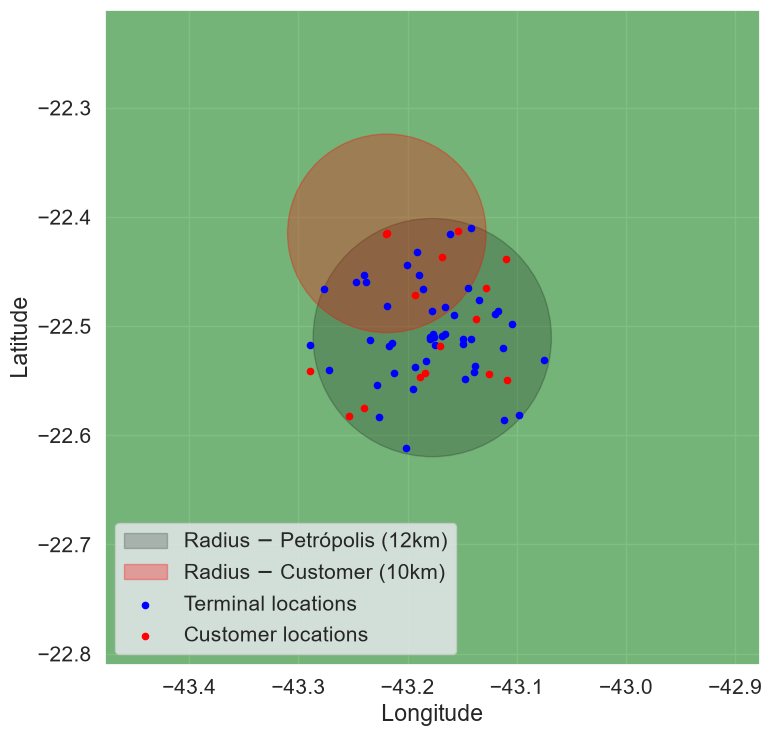

In [22]:
city_name = "Petrópolis"
billing_cities = loc_features.billing_cities_locations.reset_index()
terminal_cities = loc_features.terminal_cities_locations.reset_index()
if not ((billing_cities.name == city_name).any() and (terminal_cities.name == city_name).any()):
    # Smaller datasets: the city with most customers among those with terminals
    city_name = billing_cities[billing_cities.name.isin(terminal_cities.name)].name.value_counts().index[0]
single_city_billings = billing_cities[billing_cities.name == city_name]
city_center = (single_city_billings.iloc[0].long, single_city_billings.iloc[0].lat)

single_city_customers = customer_profiles_table.iloc[single_city_billings.index]
single_city_customers_gpd = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(
        single_city_customers.billing_long, single_city_customers.billing_lat
    )
)

single_city_term_locs = terminal_cities[terminal_cities.name == city_name]

single_city_terminals = terminal_profiles_table.iloc[single_city_term_locs.index]
single_city_terminals_gpd = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(
        single_city_terminals.terminal_long, single_city_terminals.terminal_lat
    )
)

fig, axs = plt.subplots(1, 1, figsize=(8, 8))

degrees_per_km = 1.0 / 110

brazil.plot(facecolor="green", edgecolor="black", alpha=0.5, ax=axs)

city_radius_deg = city_radius * degrees_per_km
city_circ = plt.Circle(
    city_center,
    radius=city_radius_deg,
    color="black",
    alpha=0.2,
    label=f"{T['radius']} $-$ {city_name} ({city_radius:.0f}km)",
)
axs.add_patch(city_circ)


customer = single_city_customers_gpd.iloc[0].geometry
available_terminals_radius_deg = available_terminals_radius * degrees_per_km
customer_circ = plt.Circle(
    (customer.x, customer.y),
    radius=available_terminals_radius_deg,
    color="red",
    alpha=0.3,
    label=f"{T['radius']} $-$ {T['customer']} ({available_terminals_radius:.0f}km)",
)
axs.add_patch(customer_circ)

single_city_terminals_gpd.plot(
    color="blue", markersize=20, ax=axs, label=T["terminals_locations"]
)
single_city_customers_gpd.plot(
    color="red", markersize=20, ax=axs, label=T["customers_locations"]
)

plt.xlim([city_center[0] - 0.3, city_center[0] + 0.3])
plt.ylim([city_center[1] - 0.3, city_center[1] + 0.3])

map_labels(axs)
plt.legend()
plt.tight_layout()
save_figure("simulator_city_radius")
plt.show()

### Locations distribution based on population

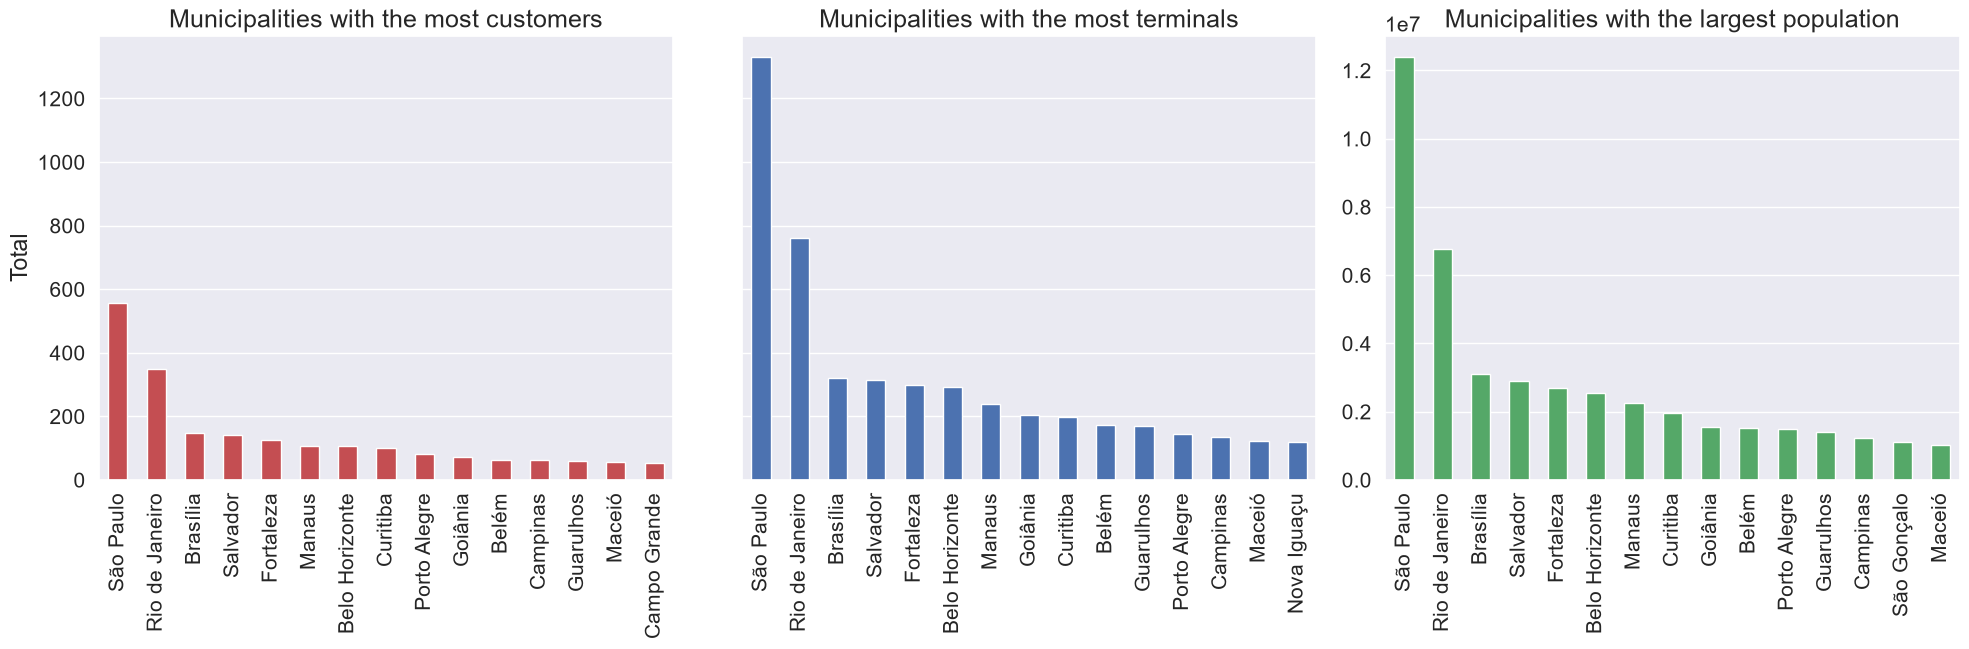

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(20, 7))

customers_cities = loc_features.billing_cities_locations["name"]
customers_cities.value_counts().nlargest(15).plot(
    kind="bar", color=sns.color_palette()[3], xlabel="", ax=axs[0]
)
axs[0].set_title(T["top_customers"], fontsize=18)
axs[0].grid(axis="x")
axs[0].set_ylabel("Total")

customers_cities = loc_features.terminal_cities_locations["name"]
customers_cities.value_counts().nlargest(15).plot(
    kind="bar", color=sns.color_palette()[0], ax=axs[1], xlabel=""
)
axs[1].set_title(T["top_terminals"], fontsize=18)
axs[1].grid(axis="x")
axs[0].sharey(axs[1])

plt.subplot(1, 3, 3)
loc_features.data["brazil_cities"][["name", "pop_21"]].nlargest(
    15, columns="pop_21"
).plot(
    x="name",
    y="pop_21",
    kind="bar",
    color=sns.color_palette()[2],
    ax=axs[2],
    xlabel="",
    legend=False,
)
axs[2].set_title(T["top_population"], fontsize=18)
axs[2].grid(axis="x")


plt.tight_layout()
save_figure("populous_cities_distribution")
plt.show()

In [24]:
cnt = int((customer_profiles_table.available_terminals.apply(len) == 0).sum())
print(f"Number of clients without available terminals: {cnt}")
print(f"% of clients without available terminals: {100 * cnt / n_customers:.2f}")

Number of clients without available terminals: 715
% of clients without available terminals: 7.15


### Number of transactions per fraud scenario

In [25]:
print(f"Number of fraudulent transactions: {transactions_df.TX_FRAUD.sum()}")
print(
    f"Percentage of fraudulent transactions: {100 * transactions_df.TX_FRAUD.mean():.2f}%"
)

Number of fraudulent transactions: 13283
Percentage of fraudulent transactions: 0.36%


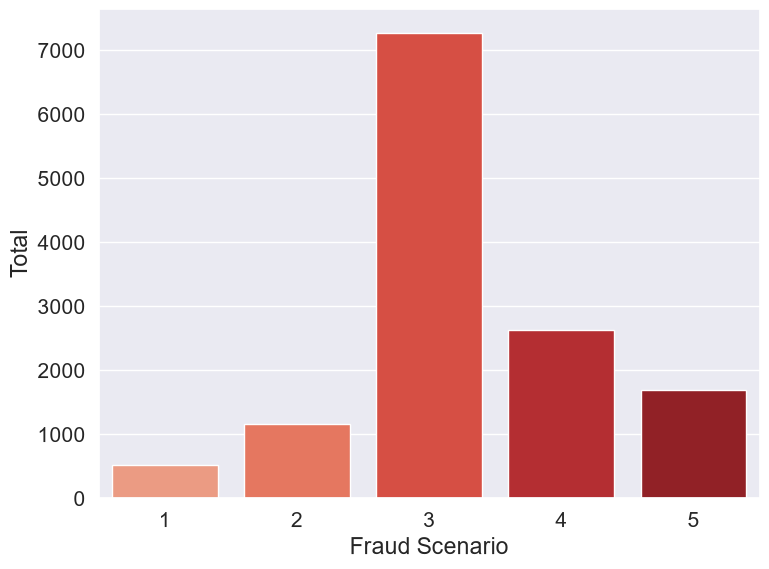

In [26]:
plt.figure(figsize=(8, 6))

sns.countplot(
    x=transactions_df["TX_FRAUD_SCENARIO"].loc[
        transactions_df["TX_FRAUD_SCENARIO"] != 0
    ],
    hue=transactions_df["TX_FRAUD_SCENARIO"].loc[
        transactions_df["TX_FRAUD_SCENARIO"] != 0
    ],
    palette=SCENARIO_PALETTE,
    legend=False,
)

plt.xlabel(T["scenario"])
plt.ylabel("Total")

plt.tight_layout()
save_figure("fraud_scenarios_count")
plt.show()

### Transactions, frauds and compromised cards per day

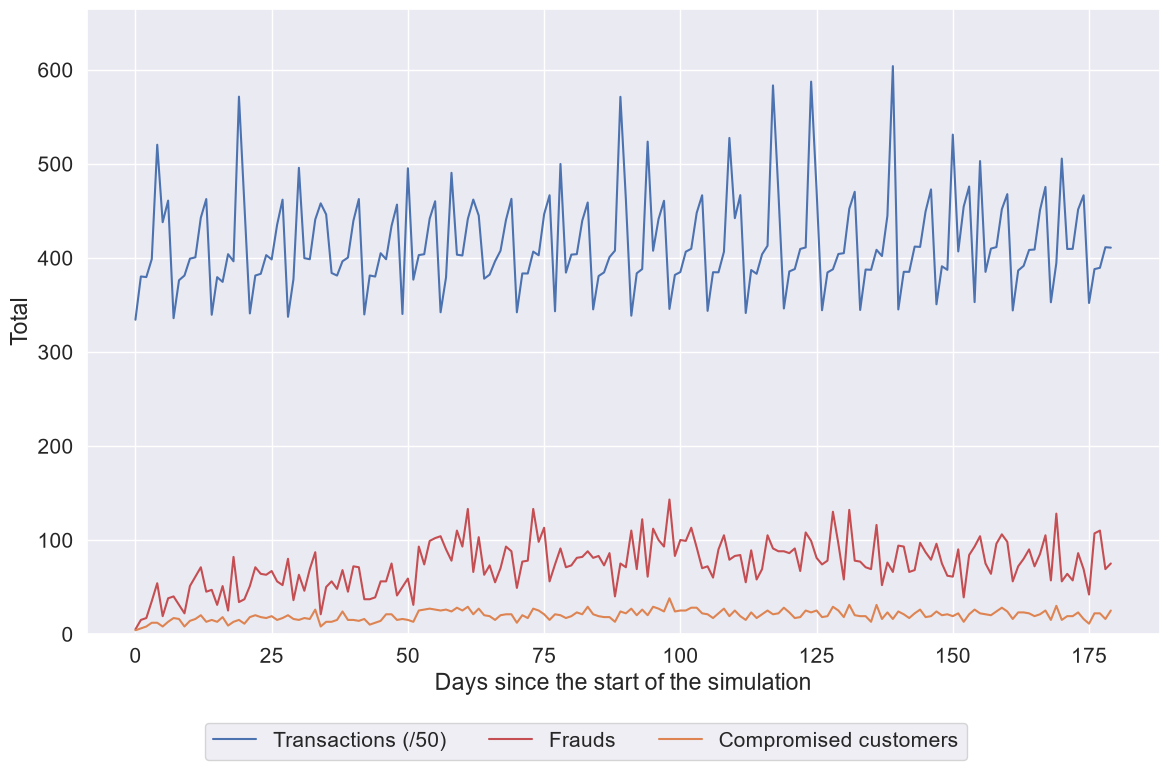

In [27]:
def get_stats(transactions_df):
    # Number of transactions per day
    nb_tx_per_day = transactions_df.groupby(["TX_TIME_DAYS"])["CUSTOMER_ID"].count()
    # Number of fraudulent transactions per day
    nb_fraud_per_day = transactions_df.groupby(["TX_TIME_DAYS"])["TX_FRAUD"].sum()
    # Number of fraudulent cards per day
    nb_fraudcard_per_day = (
        transactions_df[transactions_df["TX_FRAUD"] > 0]
        .groupby(["TX_TIME_DAYS"])
        .CUSTOMER_ID.nunique()
    )

    # Every day, also those without fraud
    days = range(transactions_df.TX_TIME_DAYS.max() + 1)
    return tuple(
        s.reindex(days, fill_value=0)
        for s in (nb_tx_per_day, nb_fraud_per_day, nb_fraudcard_per_day)
    )


(nb_tx_per_day, nb_fraud_per_day, nb_fraudcard_per_day) = get_stats(transactions_df)

n_days = len(nb_tx_per_day)
tx_stats = pd.DataFrame(
    {"value": pd.concat([nb_tx_per_day / 50, nb_fraud_per_day, nb_fraudcard_per_day])}
)
tx_stats["stat_type"] = (
    [T["transactions_50"]] * n_days
    + [T["frauds"]] * n_days
    + [T["compromised"]] * n_days
)
tx_stats = tx_stats.reset_index()

# Plotting
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

sns_plot = sns.lineplot(
    x="TX_TIME_DAYS",
    y="value",
    data=tx_stats,
    hue="stat_type",
    palette=[sns.color_palette()[0], sns.color_palette()[3], sns.color_palette()[1]],
    hue_order=[T["transactions_50"], T["frauds"], T["compromised"]],
    ax=ax,
)

plt.xlabel(T["days_since_start"])
plt.ylabel("Total")

plt.ylim([0, 1.1 * tx_stats.value.max()])

handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles=handles,
    labels=labels,
    loc="upper left",
    bbox_to_anchor=(0.1, -0.125),
    ncol=3,
)

plt.tight_layout()
save_figure("transactions_per_day")
plt.show()

### Transaction amounts per fraud scenario

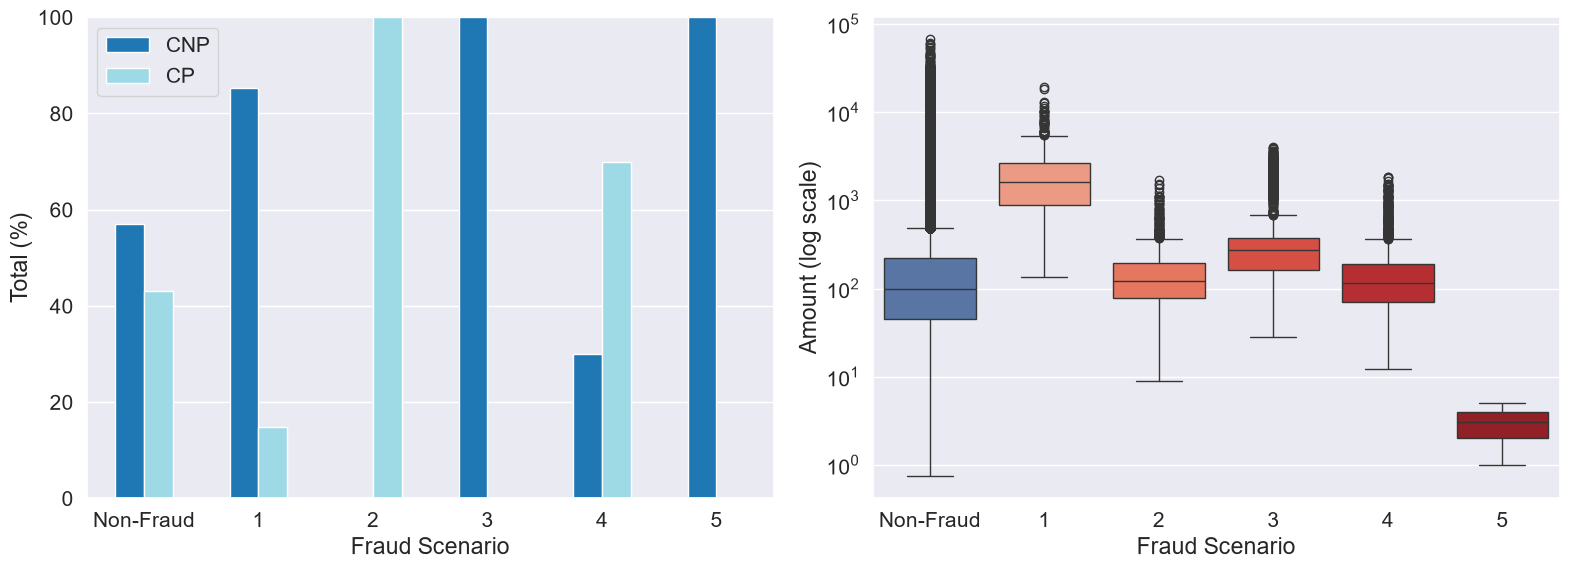

In [28]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6))

pd.crosstab(transactions_df["TX_FRAUD_SCENARIO"], transactions_df["TX_TYPE"]).apply(
    lambda x: 100 * x / x.sum(), axis=1
).plot(
    kind="bar",
    rot=0,
    ax=axs[0],
    xlabel=T["scenario"],
    ylabel="Total (%)",
    colormap="tab20",
)
axs[0].grid(axis="x")
axs[0].set_xticklabels([T["non_fraud"]] + axs[0].get_xticklabels()[1:])
axs[0].legend()
axs[0].set_ylim([0, 100])

sns.boxplot(
    flierprops={"rasterized": True},
    data=transactions_df,
    x="TX_FRAUD_SCENARIO",
    y="TX_AMOUNT",
    hue="TX_FRAUD_SCENARIO",
    legend=False,
    ax=axs[1],
    palette=PALETTE,
)
if WITH_MERCHANTS:
    axs[1].set_yscale("log")

axs[1].set_xlabel(T["scenario"])
axs[1].set_ylabel(T["amount_log"] if WITH_MERCHANTS else T["amount"])
axs[1].set_xticklabels([T["non_fraud"]] + axs[1].get_xticklabels()[1:])


plt.tight_layout()
save_figure("fraud_scenarios_type_and_amounts")
plt.show()

### Distances

In [29]:
def dist_features(transactions_df):
    billing_locs = transactions_df[["TX_BILL_LAT", "TX_BILL_LONG"]].values.astype(float)
    terminal_locs = transactions_df[["TX_TERM_LAT", "TX_TERM_LONG"]].values.astype(
        float
    )
    shipping_locs = transactions_df[["TX_SHIPP_LAT", "TX_SHIPP_LONG"]].values.astype(
        float
    )

    transactions_df["TX_DIST_BILL_TERM"] = haversine_vector(billing_locs, terminal_locs)
    transactions_df["TX_DIST_BILL_SHIPP"] = haversine_vector(
        billing_locs, shipping_locs
    )

    return transactions_df


transactions_df = dist_features(transactions_df)

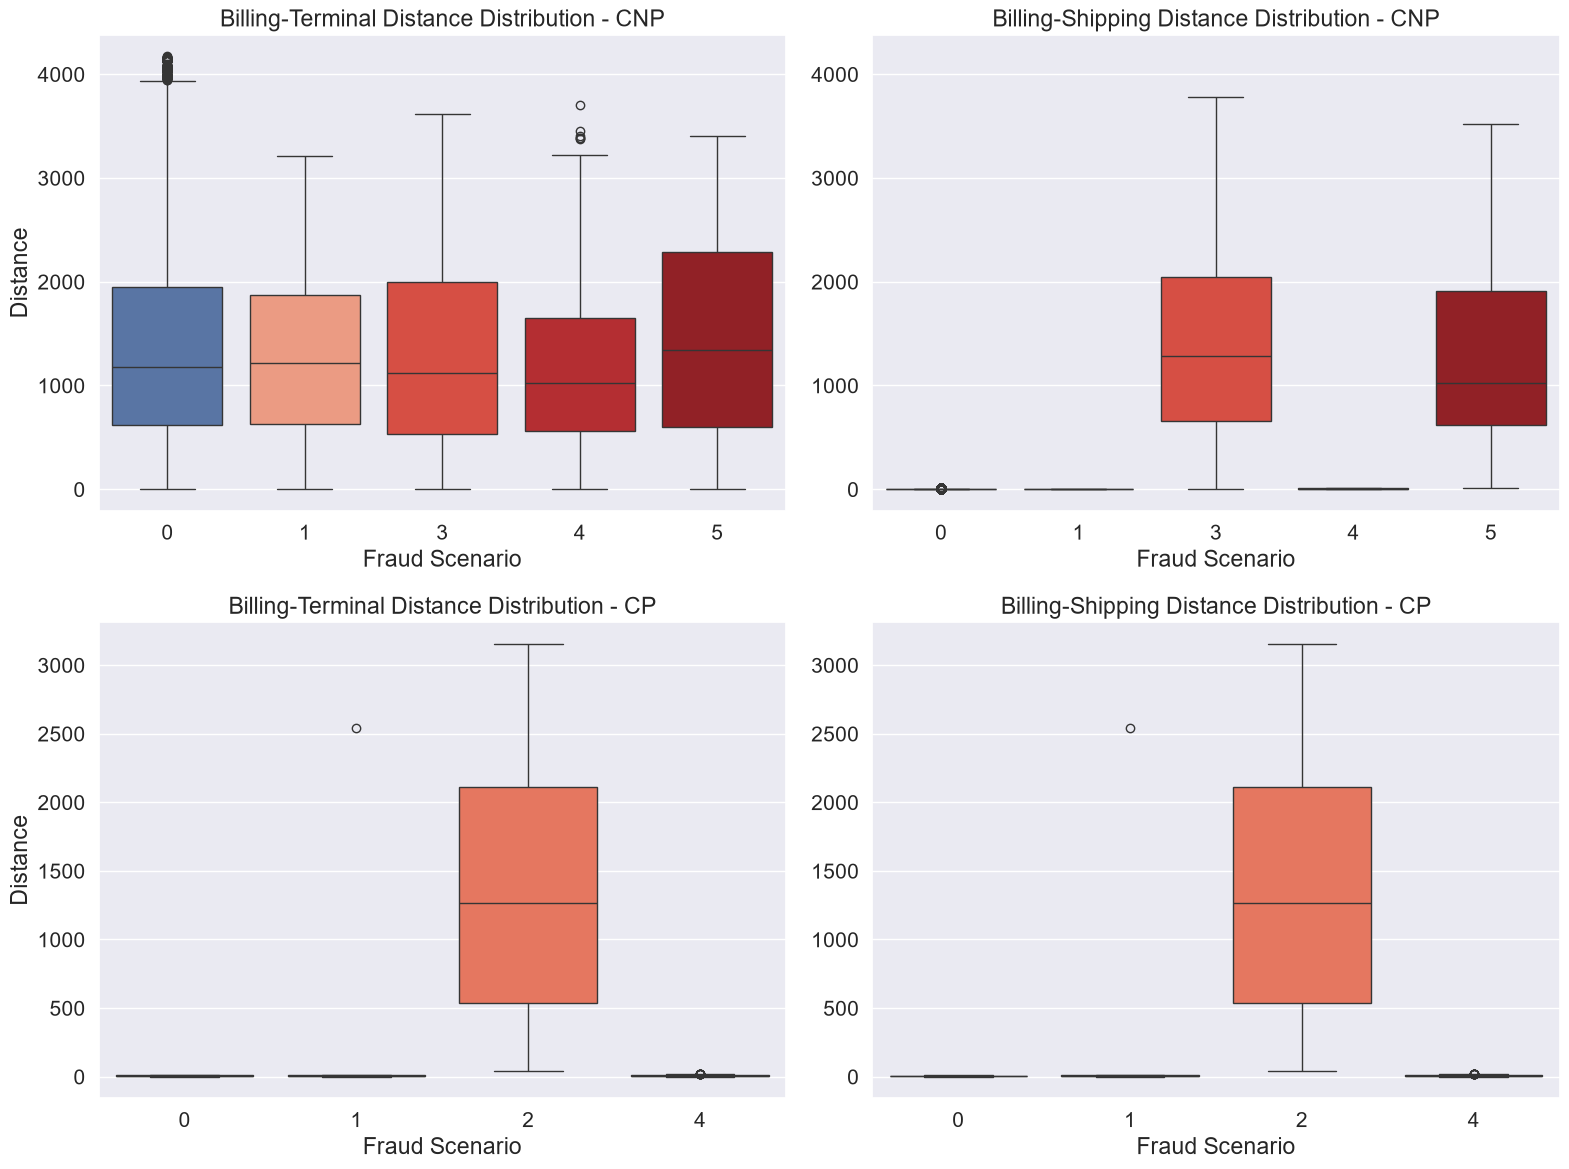

In [30]:
fig, ax = plt.subplots(2, 2, figsize=(16, 12))

cnp_transactions = transactions_df[transactions_df["TX_TYPE"] == "CNP"]
cp_transactions = transactions_df[transactions_df["TX_TYPE"] == "CP"]

sns.boxplot(
    flierprops={"rasterized": True},
    data=cnp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_TERM",
    hue="TX_FRAUD_SCENARIO",
    palette=PALETTE,
    legend=False,
    ax=ax[0, 0],
)
ax[0, 0].set_xlabel(T["scenario"])
ax[0, 0].set_ylabel(T["distance"])
ax[0, 0].set_title(T["dist_bill_term_cnp"])

sns.boxplot(
    flierprops={"rasterized": True},
    data=cnp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_SHIPP",
    hue="TX_FRAUD_SCENARIO",
    palette=PALETTE,
    legend=False,
    ax=ax[0, 1],
)
ax[0, 1].set_xlabel(T["scenario"])
ax[0, 1].set_ylabel("")
ax[0, 1].sharey(ax[0, 0])
ax[0, 1].set_title(T["dist_bill_shipp_cnp"])

sns.boxplot(
    flierprops={"rasterized": True},
    data=cp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_TERM",
    hue="TX_FRAUD_SCENARIO",
    palette=PALETTE,
    legend=False,
    ax=ax[1, 0],
)
ax[1, 0].set_xlabel(T["scenario"])
ax[1, 0].set_ylabel(T["distance"])
ax[1, 0].set_title(T["dist_bill_term_cp"])

sns.boxplot(
    flierprops={"rasterized": True},
    data=cp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_SHIPP",
    hue="TX_FRAUD_SCENARIO",
    palette=PALETTE,
    legend=False,
    ax=ax[1, 1],
)
ax[1, 1].set_xlabel(T["scenario"])
ax[1, 1].set_ylabel("")
ax[1, 1].sharey(ax[1, 0])
ax[1, 1].set_title(T["dist_bill_shipp_cp"])

plt.tight_layout()
plt.show()

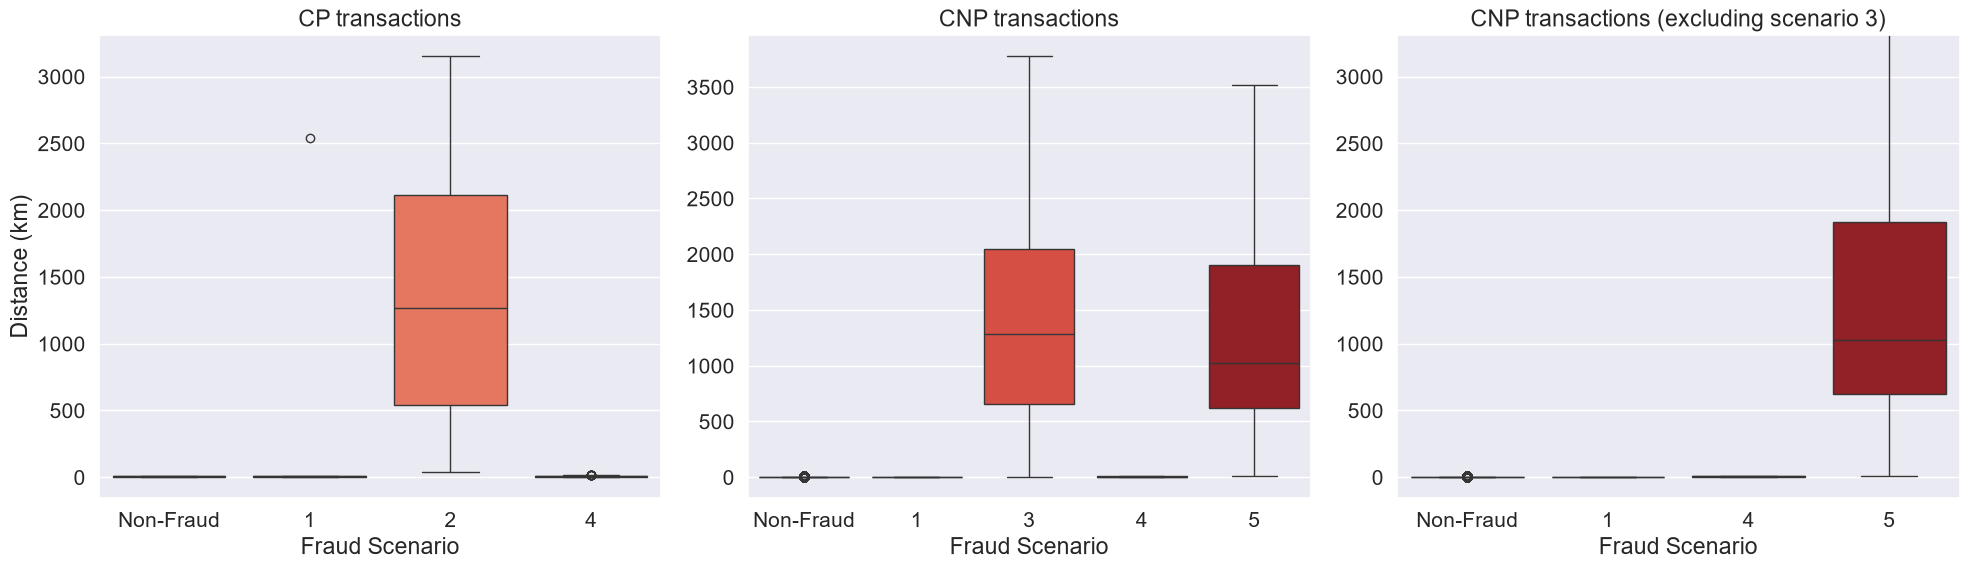

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6))


sns.boxplot(
    flierprops={"rasterized": True},
    data=cp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_SHIPP",
    hue="TX_FRAUD_SCENARIO",
    palette=PALETTE,
    legend=False,
    ax=ax[0],
)
ax[0].set_xlabel(T["scenario"])
ax[0].set_ylabel("")
ax[0].set_title(T["cp_transactions"])
ax[0].set_xticklabels([T["non_fraud"]] + ax[0].get_xticklabels()[1:])
ax[0].set_ylabel(T["distance_km"])

sns.boxplot(
    flierprops={"rasterized": True},
    data=cnp_transactions,
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_SHIPP",
    hue="TX_FRAUD_SCENARIO",
    palette=PALETTE,
    legend=False,
    ax=ax[1],
)
ax[1].set_xlabel(T["scenario"])
ax[1].set_title(T["cnp_transactions"])
ax[1].set_xticklabels([T["non_fraud"]] + ax[1].get_xticklabels()[1:])
ax[1].set_ylabel("")

sns.boxplot(
    flierprops={"rasterized": True},
    data=cnp_transactions[cnp_transactions["TX_FRAUD_SCENARIO"] != 3],
    x="TX_FRAUD_SCENARIO",
    y="TX_DIST_BILL_SHIPP",
    hue="TX_FRAUD_SCENARIO",
    palette=PALETTE,
    legend=False,
    ax=ax[2],
)
ax[2].set_xlabel(T["scenario"])
ax[2].set_ylabel("")
ax[2].set_title(T["cnp_transactions_no_s3"])
ax[2].set_xticklabels([T["non_fraud"]] + ax[2].get_xticklabels()[1:])
ax[2].sharey(ax[0])


plt.tight_layout()
save_figure("fraud_scenarios_bill_shipp_dist2")
plt.show()

### Frauds per category (with merchants)

With merchants, the fraud rate of each category, split by scenario: each scenario buys in
its own categories.

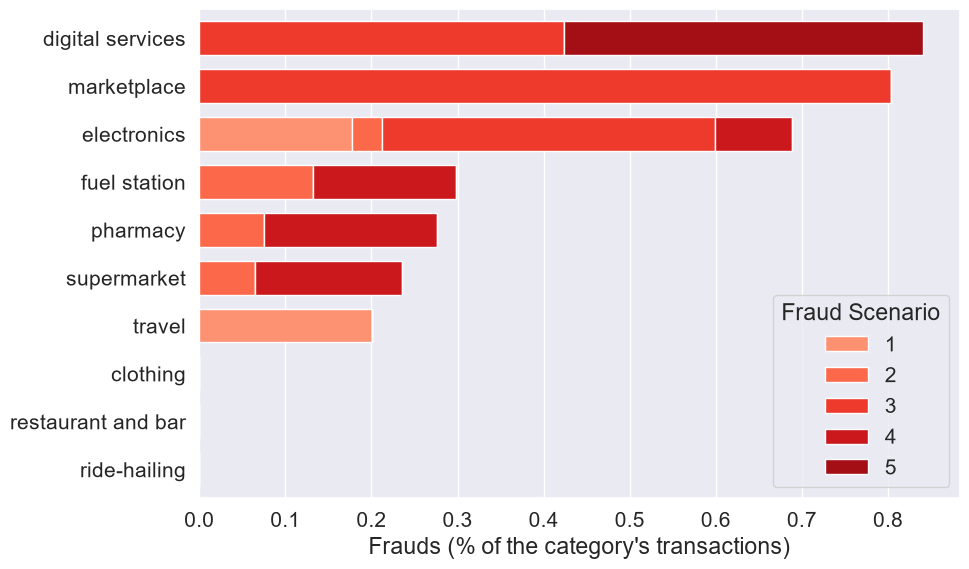

In [32]:
if WITH_MERCHANTS:
    rates = pd.crosstab(transactions_df.MERCHANT_CATEGORY, transactions_df.TX_FRAUD_SCENARIO, normalize="index")
    rates = 100 * rates.drop(columns=0).reindex(columns=list(SCENARIO_PALETTE), fill_value=0)
    rates = rates.loc[rates.sum(axis=1).sort_values().index].rename(index=T["categories"])

    fig, ax = plt.subplots(figsize=(10, 6))
    rates.plot(kind="barh", stacked=True, color=[SCENARIO_PALETTE[s] for s in rates.columns], ax=ax, width=0.7)
    ax.set_xlabel(T["frauds_share"])
    ax.set_ylabel("")
    ax.grid(axis="y")
    ax.legend(title=T["scenario"], loc="lower right")
    plt.tight_layout()
    save_figure("fraud_scenarios_per_category")
    plt.show()

# Generation time

Time to generate the `realistic` dataset, once more from the start, on this machine.

In [33]:
# Size of this notebook; with the defaults, the size of the realistic preset
size = {key: PARAMS[key] for key in presets.DEFAULT_SIZE}
benchmark = DatasetGenerator(**presets.realistic(**size))
start = time.perf_counter()
_, _, benchmark_transactions = benchmark.generate()
seconds = time.perf_counter() - start

print(
    f"synccfd {__version__} | Python {platform.python_version()} | "
    f"{platform.system()} {platform.release()} | {platform.processor()}"
)
print(
    f"realistic: {size['n_customers']:,} customers, {size['nb_days']} days, "
    f"{len(benchmark_transactions):,} transactions, {seconds:.1f} s"
)
del benchmark, benchmark_transactions

synccfd 1.0.0 | Python 3.11.4 | Windows 10 | Intel64 Family 6 Model 183 Stepping 1, GenuineIntel
realistic: 10,000 customers, 180 days, 3,735,430 transactions, 44.8 s


# Dataset statistics

The statistics of the dataset analysed above: its configuration, its size and its frauds
by scenario, with the drift and the merchants when they are on. They are saved to
`dataset_stats.json`, next to the figures.

In [34]:
def pct(part, whole):
    return round(100 * part / whole, 4) if whole else 0.0


def dataset_stats(generator, preset):
    """Statistics of the last dataset generated by ``generator``."""
    customers, terminals, tx = generator.customer_profiles, generator.terminal_profiles, generator.transactions
    config = generator.config
    frauds = tx[tx.TX_FRAUD == 1]
    n_tx = len(tx)
    stats = {
        "synccfd_version": config["synccfd_version"],
        "preset": preset,
        "config": config,
        "dataset": {
            "customers": len(customers),
            "terminals": len(terminals),
            "transactions": n_tx,
            "legitimate_transactions": n_tx - len(frauds),
            "fraudulent_transactions": len(frauds),
            "fraud_rate_pct": pct(len(frauds), n_tx),
            "cp_share_pct": pct(int((tx.TX_TYPE == "CP").sum()), n_tx),
            "customers_with_fraud": int(frauds.CUSTOMER_ID.nunique()),
            "customers_with_fraud_pct": pct(frauds.CUSTOMER_ID.nunique(), len(customers)),
            "customers_without_reachable_terminal_pct": pct(
                int((customers.available_terminals.apply(len) == 0).sum()), len(customers)
            ),
        },
        "fraud_by_scenario": {},
    }
    for scenario, rows in frauds.groupby("TX_FRAUD_SCENARIO"):
        entry = {
            "transactions": len(rows),
            "rate_pct": pct(len(rows), n_tx),
            "share_of_frauds_pct": pct(len(rows), len(frauds)),
            "victims": int(rows.CUSTOMER_ID.nunique()),
            "cp_share_pct": pct(int((rows.TX_TYPE == "CP").sum()), len(rows)),
            "median_amount": round(float(rows.TX_AMOUNT.median()), 2),
        }
        if "GT_CAMPAIGN_ID" in rows:
            entry["campaigns"] = int(rows.GT_CAMPAIGN_ID.nunique())
        stats["fraud_by_scenario"][str(int(scenario))] = entry

    if "GT_DRIFT_TYPE" in customers:
        counts = customers.GT_DRIFT_TYPE.value_counts()
        legit = tx[tx.TX_FRAUD == 0]
        stats["drift"] = {
            "customers_by_type": {
                kind: {"customers": int(n), "pct": pct(n, len(customers))} for kind, n in counts.items()
            },
            "customers_with_drift_pct": pct(int((customers.GT_DRIFT_TYPE != "none").sum()), len(customers)),
            "relocated_customers": int(customers.GT_RELOCATED.sum()),
            "legitimate_transactions_in_regime_b_pct": pct(int((legit.GT_REGIME == "B").sum()), len(legit)),
        }

    if generator.merchant_profiles is not None:
        merchants = generator.merchant_profiles
        by_category = merchants.groupby(["MERCHANT_CATEGORY", "channel"]).size()
        share = tx.MERCHANT_CATEGORY.value_counts()
        cp = tx[tx.TX_TYPE == "CP"].MERCHANT_CATEGORY.value_counts()
        fraud_share = frauds.MERCHANT_CATEGORY.value_counts()
        stats["merchants"] = {
            "merchants": len(merchants),
            "physical": int((merchants.channel == "CP").sum()),
            "online": int((merchants.channel == "CNP").sum()),
            "by_category": {
                category: {
                    "physical_merchants": int(by_category.get((category, "CP"), 0)),
                    "online_merchants": int(by_category.get((category, "CNP"), 0)),
                    "transactions_pct": pct(int(share.get(category, 0)), n_tx),
                    "cp_share_pct": pct(int(cp.get(category, 0)), int(share.get(category, 0))),
                    "frauds_pct": pct(int(fraud_share.get(category, 0)), len(frauds)),
                }
                for category in generator.merchant_config.names
            },
        }
    return stats


stats = dataset_stats(generator, PRESET)
stats_path = FIG_ROOT / "dataset_stats.json"
with open(stats_path, "w", encoding="utf-8", newline="\n") as f:
    f.write(json.dumps(stats, indent=2, ensure_ascii=False) + "\n")
print(f"{stats_path}: {stats['dataset']['transactions']:,} transactions")
stats["dataset"]

figures\dataset_stats.json: 3,735,430 transactions


{'customers': 10000,
 'terminals': 20160,
 'transactions': 3735430,
 'legitimate_transactions': 3722147,
 'fraudulent_transactions': 13283,
 'fraud_rate_pct': 0.3556,
 'cp_share_pct': 43.0033,
 'customers_with_fraud': 1920,
 'customers_with_fraud_pct': 19.2,
 'customers_without_reachable_terminal_pct': 7.15}